# Lending Game — Part 8: Pricing the new applications and writing the submission

The last step of Stage 1:

1. **Predict**: our default probability `p_own` for each of the 100,000 new applicants. This was done
   in Part 2 with the selected model (spline logistic on public variables + `signal3`, refitted on
   all 100,000 past loans), and saved in `data/predictions/applications_own.csv`.
2. **Price**: apply the rule chosen in Part 7, **R4** (break-even + a margin that rises with risk, no
   cutoff), saved in `data/pricing/final_rule.json`.
3. **Submit**: write the CSV the course asks for, with one row per application and two columns:
   `id` (1 to 100,000) and `rate` (decimal, at most 1, left empty when we make no offer).
   Then check it against those rules.

## 1. Inputs

In [1]:
import sys
sys.path.append("..")  # make src/ importable from analysis/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import NEW_APPS_R1, DATA_PREDICTIONS
from src.pricing_rules import load_pricing_data, be, smooth_bin_margins
from src.submission_round_1 import (SUBMISSION_FILE, load_final_rule, make_submission, check_submission,
                            write_submission)
from src import model_plots as mp

mp.set_style()
pd.set_option("display.width", 160)

raw = pd.read_csv(NEW_APPS_R1)                                            # the course's file
apps = pd.read_csv(DATA_PREDICTIONS / "applications_own.csv", index_col="id")   # Part 2: p_own
validation = pd.read_csv(DATA_PREDICTIONS / "validation_selected.csv", index_col="row_id")

print(f"applications file : {len(raw):,} rows, ids {raw['id'].min()} to {raw['id'].max()}, "
      f"{raw['id'].nunique():,} unique")
print(f"our predictions   : {len(apps):,} rows, same ids: {set(apps.index) == set(raw['id'])}")

compare = pd.DataFrame({"new applicants": apps["p_own"].describe(percentiles=[.1, .5, .9, .99]),
                        "validation (Part 2)": validation["p_own"].describe(percentiles=[.1, .5, .9, .99])}).drop("count")
display(compare.style.format("{:.2%}"))

applications file : 100,000 rows, ids 1 to 100000, 100,000 unique
our predictions   : 100,000 rows, same ids: True


,new applicants,validation (Part 2)
mean,9.96%,9.96%
std,7.74%,7.69%
min,0.01%,0.01%
10%,1.29%,1.26%
50%,8.67%,8.71%
90%,20.45%,20.36%
99%,33.69%,32.86%
max,50.20%,46.47%


* The applications file has exactly 100,000 applicants with ids 1 to 100,000, and we have a prediction
  for each of them.
* **The new applicants look like the validation set**: same mean predicted default probability
  (9.96%), same median (8.7%) and the same spread. Our model, and the rule tuned on these
  probabilities, apply to the new applicants without any adjustment.
* One applicant (id 23772) has $p_{own} = 50.2\%$, above the 50% limit; the validation maximum was
  46.5%.

## 2. The final rule

In [2]:
train = load_pricing_data("train")   # load_tuned_rules needs it (only R7 uses it)
rule = load_final_rule(train)
print(f"final rule: {rule.family}")

params = rule.params
curve = smooth_bin_margins(params["centres"], params["margins"])
bands = pd.DataFrame({"p_own from": [0.0] + list(params["edges"]),
                      "p_own to": list(params["edges"]) + [0.5],
                      "margin over break-even": curve(np.asarray(params["centres"]))})
display(bands.style.format("{:.2%}"))
print(f"rate floor {params['floor']:.1%}; no offer when p_own >= 0.5 or when the rate would exceed 100%")

final rule: R4


,p_own from,p_own to,margin over break-even
0,0.00%,1.22%,1.75%
1,1.22%,2.75%,1.75%
2,2.75%,4.47%,2.00%
3,4.47%,6.45%,3.17%
4,6.45%,8.69%,3.17%
5,8.69%,11.10%,3.17%
6,11.10%,13.28%,16.88%
7,13.28%,15.42%,16.88%
8,15.42%,20.55%,19.38%
9,20.55%,50.00%,19.38%


rate floor 0.5%; no offer when p_own >= 0.5 or when the rate would exceed 100%


**R4**, chosen in Part 7: the break-even rate $be(p) = p/(1-p)$ plus a margin that rises with
predicted risk:

* **1.75 points** below 2.75%;
* **2 points** up to 4.5%;
* **3.2 points** up to 11%;
* **17–19 points** above, deliberately high.

R4 does not refuse the risky applicants; it quotes them a high rate. If the competitors lend to them
cheaply, these quotes rarely win; if the competitors refuse them, we are their only lender and the
high rate pays for the risk (Part 7). The margin curve is the one tuned in Part 6, rebuilt from
`data/pricing/final_rule.json`.

## 3. Pricing the 100,000 applicants

,applicants
offer,99946
no offer: rate would exceed 100%,53
no offer: p_own >= 0.5,1


,applicants,mean_p,offers,mean_rate,mean_break_even,mean margin
band,,,,,,
< 2.75%,"19,615",1.29%,"19,615",3.08%,1.31%,1.77%
2.75-4.5%,"10,482",3.59%,"10,482",5.84%,3.73%,2.11%
4.5-11%,"29,661",7.58%,"29,661",11.85%,8.24%,3.60%
11-15%,"18,745",12.98%,"18,745",30.82%,14.93%,15.89%
15-50%,"21,496",21.61%,"21,443",47.27%,28.33%,18.94%
>= 50%,1,50.20%,0,-,-,-


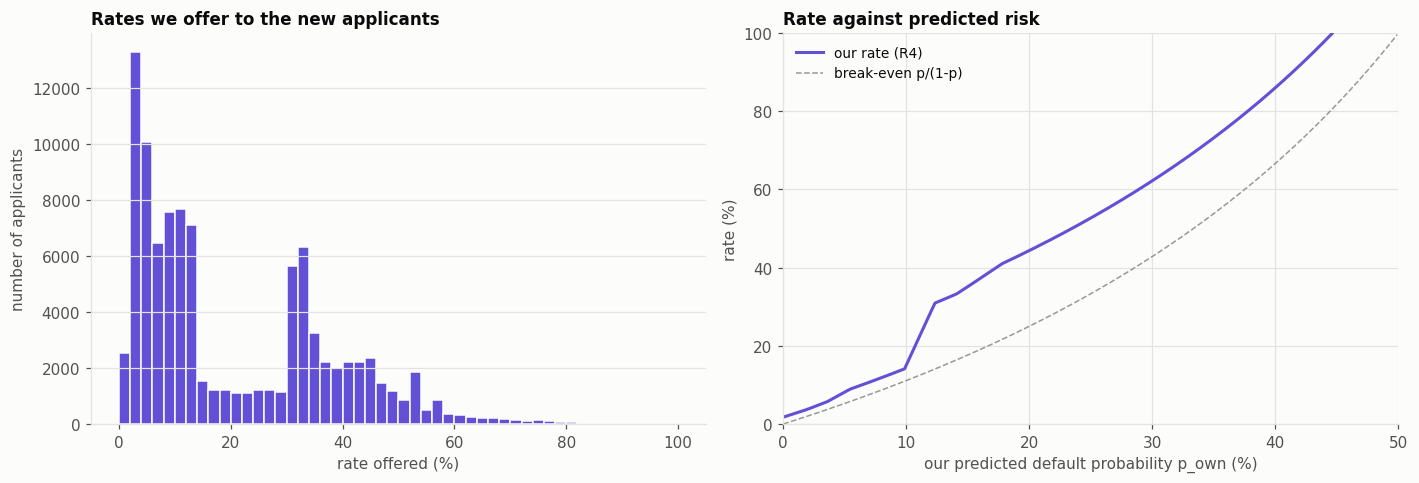

In [3]:
rates = rule(apps)                          # our rate per applicant, NaN = no offer
p = apps["p_own"]

reason = pd.Series("offer", index=apps.index)
reason[p >= 0.5] = "no offer: p_own >= 0.5"
reason[(p < 0.5) & rates.isna()] = "no offer: rate would exceed 100%"
display(reason.value_counts().to_frame("applicants"))

band_labels = ["< 2.75%", "2.75-4.5%", "4.5-11%", "11-15%", "15-50%", ">= 50%"]
band = pd.cut(p, [0, 0.0275, 0.045, 0.11, 0.15, 0.5, 1.0], labels=band_labels, right=False)
by_band = pd.DataFrame({"band": band, "p": p, "rate": rates, "be": be(p.to_numpy())}).groupby(
    "band", observed=False).agg(applicants=("p", "size"), mean_p=("p", "mean"),
                                offers=("rate", "count"), mean_rate=("rate", "mean"),
                                mean_break_even=("be", "mean"))
by_band["mean margin"] = by_band["mean_rate"] - by_band["mean_break_even"]
display(by_band.style.format({"applicants": "{:,}", "offers": "{:,}", "mean_p": "{:.2%}",
                              "mean_rate": "{:.2%}", "mean_break_even": "{:.2%}",
                              "mean margin": "{:.2%}"}, na_rep="-"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.hist(100 * rates.dropna(), bins=np.arange(0, 102, 2), color=mp.SINGLE_COLOR,
        edgecolor=mp.SURFACE, linewidth=1)
ax.set_xlabel("rate offered (%)")
ax.set_ylabel("number of applicants")
ax.set_title("Rates we offer to the new applicants")
ax.grid(axis="x", visible=False)

ax = axes[1]
order = np.argsort(p.to_numpy())
ax.plot(100 * p.to_numpy()[order], 100 * rates.to_numpy()[order], color=mp.SINGLE_COLOR,
        label="our rate (R4)")
grid = np.linspace(0, 0.499, 300)
ax.plot(100 * grid, 100 * be(grid), color=mp.REFERENCE, lw=1, ls="--", label="break-even p/(1-p)")
ax.set_xlim(0, 50)
ax.set_ylim(0, 100)
ax.set_xlabel("our predicted default probability p_own (%)")
ax.set_ylabel("rate (%)")
ax.set_title("Rate against predicted risk")
ax.legend()
fig.tight_layout()
plt.show()

* **We make an offer to 99,946 of the 100,000 applicants.** The 54 without an offer are:
  * 1 applicant with $p_{own} \ge 50\%$, whose break-even rate would exceed 100%;
  * 53 applicants with $p_{own}$ between about 45% and 50%, whose rate would exceed 100%.
* **Two segments, as designed:**
  * **The safer 60% of applicants** ($p_{own}$ below 11%) get rates close to break-even: on average
    3.1% for the safest fifth, 5.8% and 11.9% above that, i.e. 1.8 to 3.6 points of margin. This is
    where we expect to win most of our loans.
  * **The riskier 40%** get high rates, 31% on average for $p_{own}$ between 11% and 15% and 47% above,
    16–19 points over break-even. We expect to win few of them unless the competitors refuse them.
* The 0.5% floor never binds: the lowest rate offered is 1.76%. The highest is 99.9%.
* The rate curve (right) sits a couple of points above break-even up to $p_{own} \approx 11\%$, then
  jumps to the high-margin segment. That jump explains the gap in the histogram (left) between the
  two groups of rates.

## 4. Writing and checking the submission file

In [4]:
submission = make_submission(rates)
summary = check_submission(submission, raw["id"])      # raises if any course rule is broken
path = write_submission(submission)
print(f"written {path.relative_to(path.parents[1])}")
display(pd.Series({"applications": f"{summary['applications']:,}", "offers": f"{summary['offers']:,}",
                   "no offer (empty rate)": f"{summary['no offer']:,}",
                   "lowest rate": f"{summary['min rate']:.2%}", "median rate": f"{summary['median rate']:.2%}",
                   "highest rate": f"{summary['max rate']:.2%}"}).to_frame("value"))

# Read the file back exactly as it will be sent, and check it again.
reread = pd.read_csv(path)
check_submission(reread, raw["id"])
print("file re-read: same ids:", reread["id"].tolist() == submission["id"].tolist(),
      "| same rates (6 decimals):", np.allclose(reread["rate"], submission["rate"], atol=1e-6, equal_nan=True),
      "| empty cells:", int(reread["rate"].isna().sum()))
print()
print(open(path).read()[:300])

written submissions/Lender3_Round1_submission.csv


,value
applications,"100,000"
offers,"99,946"
no offer (empty rate),54
lowest rate,1.76%
median rate,12.65%
highest rate,99.91%


file re-read: same ids: True | same rates (6 decimals): True | empty cells: 54

id,rate
1,0.041016
2,0.120825
3,0.041385
4,0.128803
5,0.316272
6,0.316340
7,0.026785
8,0.481060
9,0.052471
10,0.324646
11,0.134588
12,0.573078
13,0.043304
14,0.122863
15,0.037424
16,0.054738
17,0.023485
18,0.393265
19,0.047936
20,0.088542
21,0.022103
22,0.092068
23,0.038546
24,0.310514
25,0.322029
2


## 5. Summary


* **Submission file:** `submissions/Lender3_Round1_submission.csv`, 100,000 rows, 99,946 offers,
  54 empty rates. It passes every format check.
* **Pipeline:**
  * Part 2's model predicts $p_{own}$ (spline logistic, public variables + `signal3`);
  * Part 7's rule **R4** prices it: break-even plus about 2–3 points for $p_{own}$ below 11%, plus
    17–19 points above, no offer above 100%.